# Recapture: what a screen attack does to an image, and a simulator for it

The training set has no real attacks. Attacks for training are synthesised from bona fide images by a physical simulator (`screenpad/synth/recapture.py`). This notebook:

1. Measures, on the **6 dev twin pairs only**, what recapture changes: geometry, the screen's pixel grid, tone and colour, fine detail.
2. Checks which of those changes survive the face crop that every model sees.
3. Shows the simulator stage by stage.
4. Compares simulated recaptures of the dev bona fide images with their real attacks, and checks the resample-ratio shortcut.

**Data discipline.** Only dev pairs are measured. The 17 test attacks are not opened here. Simulator ranges in `configs/synth.yaml` were set from these measurements and then widened on purpose, so the simulator randomises conditions instead of copying six photos.

Prerequisites: `screenpad splits`, `screenpad cache` (aligned crops), `screenpad synth --splits dev --variants 5 --set synth.camera_only_frac=1.0`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from screenpad.config import load_config
from screenpad.utils import limit_threads
from screenpad.data.io import load_image
from screenpad.data.cache import load_cache, cache_frame
from screenpad.data.preprocess import FaceCropper
from screenpad.eda.pairs import register, warp_to_bona, tone_curves, grid_peak
from screenpad.eda.stats import pixel_stats_frame
from screenpad.synth.recapture import RecaptureParams, _display, render_screen, camera, linear_to_srgb
from screenpad.synth.generate import simulate, CAMERA_ONLY

limit_threads(6)
cfg = load_config()
SEED = int(cfg.seed)
ROOT = Path(cfg.data.root)
RANGES = cfg.synth.ranges

BONAFIDE_C, CAMONLY_C, ATTACK_C, SYNTH_C = "#2a78d6", "#8fb8e8", "#eb6834", "#a8431a"
INK_2, GRID, SURFACE = "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "figure.dpi": 110,
})

splits = pd.read_csv(cfg.data.splits, dtype={"id": str})
dev = splits[splits.split == "dev"]
DEV_IDS = sorted(dev.id.unique())
phone = dev[dev.label == 1].set_index("id").exif_model
pairs = {i: (np.asarray(load_image(ROOT / f"Bonafide/{i}.png")), np.asarray(load_image(ROOT / f"Screens/{i}.png"))) for i in DEV_IDS}

## 1. Geometry: how each attack maps onto its twin

Each attack is registered to its bona fide twin with SIFT features and a RANSAC homography. From the homography: how many camera pixels cover one source pixel, and how far the displayed image is from a square (keystone from tilting the phone).

In [2]:
rows, H = [], {}
fc = FaceCropper()
for i, (b, a) in pairs.items():
    H[i], inl = register(b, a)
    Hi = np.linalg.inv(H[i])
    c = cv2.perspectiveTransform(np.float32([[[0, 0], [1023, 0], [1023, 1023], [0, 1023]]]), Hi)[0]
    sides = np.linalg.norm(np.roll(c, -1, 0) - c, axis=1)
    rows.append({"id": i, "phone": phone[i], "attack size": f"{a.shape[1]}x{a.shape[0]}", "inliers": inl,
                 "camera px per source px": sides.mean() / 1024,
                 "keystone (max/min side)": sides.max() / sides.min()})
geo = pd.DataFrame(rows).set_index("id")
display(geo.round(2))

[ WARN:0@1.554] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


,phone,attack size,inliers,camera px per source px,keystone (max/min side)
id,,,,,
00998,iPhone 15,2637x2564,463,2.53,1.06
10673,iPhone 15,2891x2803,2927,2.79,1.02
10741,iPhone 15,2784x3013,2816,2.99,1.01
10881,SM-A127F,2446x2389,1380,2.31,1.02
10889,SM-A127F,1980x2358,132,2.44,1.17
10960,SM-A127F,2650x2670,571,2.57,1.01


The attack files have been cropped to roughly the displayed image, so there is no bezel or background. The phone covered each source pixel with 2.3 to 3.0 camera pixels. Tilt is mild (keystone 1-17%). After a face-centred crop, the tilt shows up as a small perspective change across the face, which the simulator reproduces with a small random tilt.

## 2. At native resolution the screen is plainly visible

Matched patches, each 256 camera pixels wide, from the centre of the face. The bona fide patch is resampled to the same field of view.

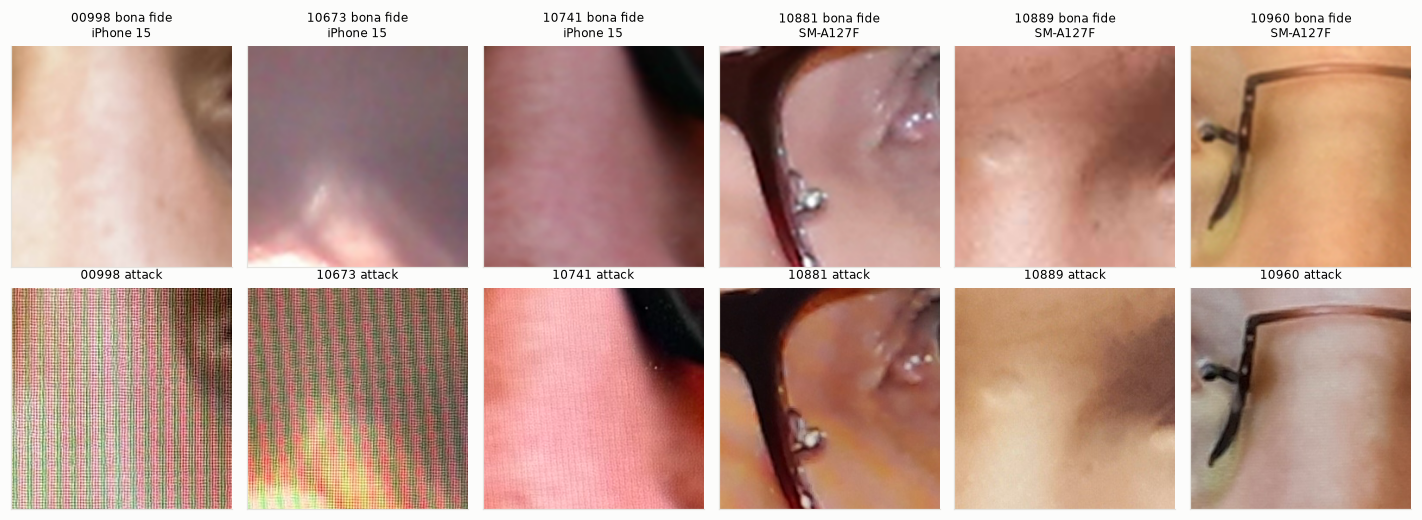

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for k, i in enumerate(DEV_IDS):
    b, a = pairs[i]
    det = fc.detect(a)
    x, y, w, h = det.box
    cx, cy = int(x + w / 2), int(y + h * 0.4)
    pa = a[cy - 128:cy + 128, cx - 128:cx + 128]
    bx, by = cv2.perspectiveTransform(np.float32([[[cx, cy]]]), H[i])[0, 0]
    half = int(128 / geo.loc[i, "camera px per source px"])
    pb = cv2.resize(b[int(by) - half:int(by) + half, int(bx) - half:int(bx) + half], (256, 256), interpolation=cv2.INTER_CUBIC)
    for r, (im, lab) in enumerate(((pb, "bona fide"), (pa, "attack"))):
        axes[r, k].imshow(im); axes[r, k].set_xticks([]); axes[r, k].set_yticks([]); axes[r, k].grid(False)
        axes[r, k].set_title(f"{i} {lab}" + (f"\n{phone[i]}" if r == 0 else ""), fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
peaks = []
for i in DEV_IDS:
    a = pairs[i][1]
    x, y, w, h = fc.detect(a).box
    peaks.append({"id": i, "phone": phone[i], **grid_peak(a, (int(x + w / 2), int(y + h / 2)))})
peaks = pd.DataFrame(peaks).set_index("id")
display(peaks.round(3))

,phone,fx,fy,period_px,excess_log10
id,,,,,
00998,iPhone 15,-0.295,-0.002,3.391,5.945
10673,iPhone 15,-0.301,-0.006,3.324,5.687
10741,iPhone 15,0.143,-0.014,6.982,4.448
10881,SM-A127F,0.070,-0.023,13.492,3.946
10889,SM-A127F,-0.500,0.000,2.000,4.005
10960,SM-A127F,0.006,0.273,3.656,4.434


Every dev attack has one dominant periodic component, 3.9 to 5.9 orders of magnitude above the median spectral power. On the iPhone pairs it is the vertical RGB stripe grid of an LCD, with a period of about 3.3 camera pixels. On the Samsung pairs it is weaker, softer, or aliased into low-frequency moiré (period 13.5 px for 10881; 2 px, the sampling limit, for 10889). Combined with the geometry above, this gives the screen's resolution relative to the source: about 0.4 to 0.8 screen pixels per FFHQ pixel. The 1024-px image was shown smaller than its native size.

## 3. Tone and colour

For each pair, the median attack value per bona fide value bin and channel, after registration. A perfect copy would lie on the diagonal.

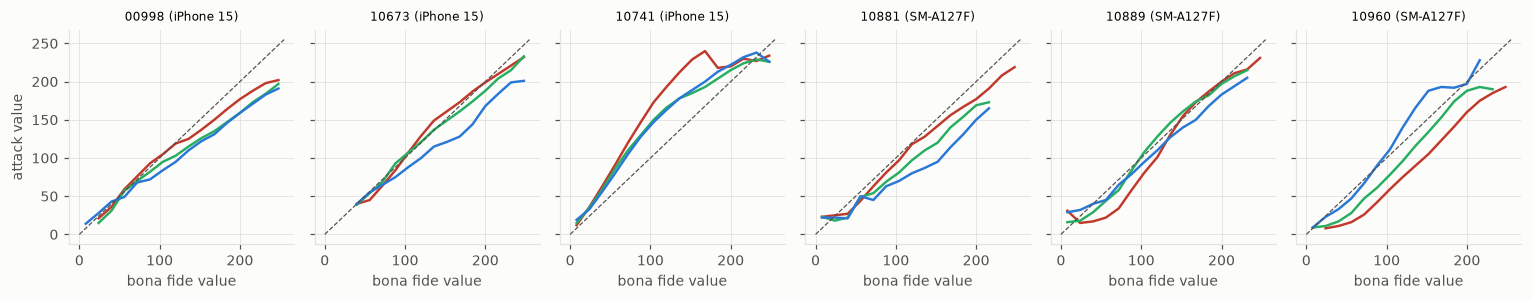

In [5]:
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8), sharey=True)
xs = np.arange(0, 256, 16) + 8
for ax, i in zip(axes, DEV_IDS):
    b, a = pairs[i]
    curves = tone_curves(b, warp_to_bona(a, H[i], (b.shape[1], b.shape[0])))
    for c, col in zip(curves, ("#c0392b", "#27ae60", "#2a78d6")):
        ax.plot(xs, c, color=col, lw=1.6)
    ax.plot([0, 255], [0, 255], color=INK_2, lw=0.8, ls="--")
    ax.set_title(f"{i} ({phone[i]})", fontsize=8); ax.set_xlabel("bona fide value")
axes[0].set_ylabel("attack value")
plt.tight_layout(); plt.show()

The transfer is different for every pair, in both directions:
- blacks are lifted (backlight leak, room light on the glass) on some pairs and crushed on others;
- whites are compressed below 255 on most;
- channel curves separate, giving colour casts towards warm or cool.

So colour and tone are not a consistent cue: the simulator randomises display gamma, black level, white point and saturation, and the camera's white balance and contrast, over wide ranges.

## 4. What survives the face crop

Models see 384-px aligned face crops. Attack crops are downsampled 3-11x from camera resolution, and area-averaging over a 3-4 px window averages one screen-pixel period away. The same grid measurement on the crops:

In [6]:
real = load_cache(Path(cfg.data.cache_dir) / "crops_tight_384_aligned.npz")
fr = cache_frame(real)
rows = []
for i in DEV_IDS:
    for lab in (0, 1):
        k = np.flatnonzero((fr.id == i) & (fr.label == lab))[0]
        rows.append({"id": i, "label": ["bona fide", "attack"][lab], "crop downsample": fr.info_resample_ratio[k],
                     "grid strength in crop": grid_peak(real["images"][k], (192, 192), n=384)["excess_log10"]})
crop_peaks = pd.DataFrame(rows).pivot(index="id", columns="label")
crop_peaks.columns = [f"{a} ({b})" for a, b in crop_peaks.columns]
crop_peaks["grid strength native (attack)"] = peaks.excess_log10
display(crop_peaks.round(2))

,crop downsample (attack),crop downsample (bona fide),grid strength in crop (attack),grid strength in crop (bona fide),grid strength native (attack)
id,,,,,
00998,4.75,1.97,4.09,4.06,5.95
10673,5.13,1.82,4.28,3.82,5.69
10741,5.11,1.81,3.66,3.94,4.45
10881,4.44,1.87,3.62,3.77,3.95
10889,4.20,1.80,3.87,3.68,4.01
10960,4.92,1.91,3.27,3.39,4.43


At native resolution the grid stands 4-6 orders of magnitude above background. In the crops, this measure is the same for attacks and their twins (3.3-4.3 for both): the strongest periodic component in a crop is no longer the screen. This is consistent with the EDA, where only 2 of 6 dev crops showed clear spectral peaks. Two consequences:

- A model working only on 384-px crops gets a weakened version of the strongest cue. Native-resolution patches are a candidate model input, to be decided at the review before training.
- The simulator must reproduce the grid **and** the heavy downsampling, so synthetic crops weaken the grid the same way. It does this by simulating at camera resolution and then running the standard detect-align-crop pipeline on the simulated photo.

## 5. The simulator, stage by stage

One **train** bona fide image (not a dev image) through the simulator, with one random draw of parameters. Top row: full frame. Bottom row: a 128-px patch at native camera resolution.

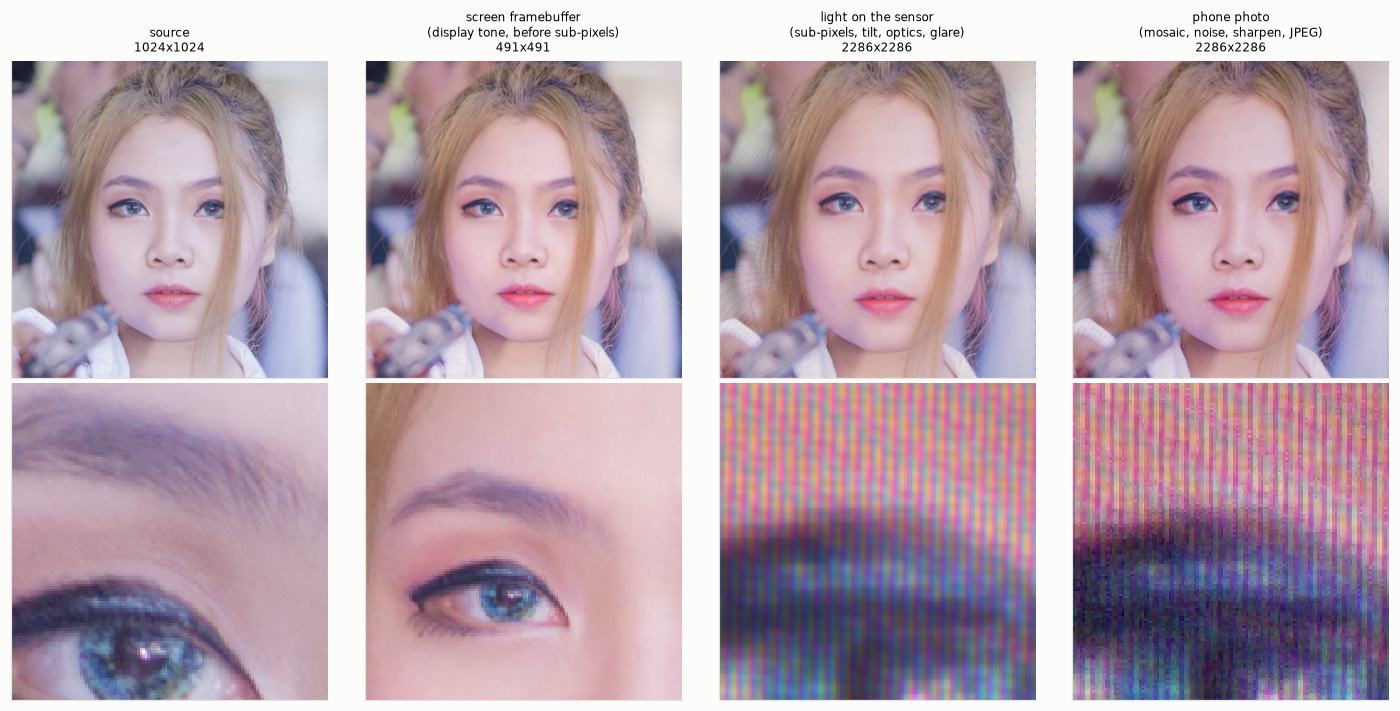

{'layout': 'bgr_stripe', 'screen_per_src': 0.48, 'cam_per_src': 2.232, 'fill': 0.854, 'display_gamma': 2.228, 'saturation': 1.277, 'white_point': (1.1157714242448353, 1.0, 0.895194484815367), 'black_level': 0.001, 'veil': 0.005, 'glare': 0.0, 'glare_xy': (0.8431070419421323, 0.5059752810585223), 'glare_sigma': 0.273, 'dust': 28, 'tilt': 0.05, 'rotation': 0.009, 'blur': 1.408, 'vignette': 0.058, 'camera_exposure': 0.821, 'camera_wb': (1.0183643657096115, 1.0, 1.0487031061691927), 'camera_shot': 0.0, 'camera_read': 0.0, 'camera_demosaic': 137, 'camera_denoise': 0.0, 'camera_contrast': 0.369, 'camera_sharpen_amount': 1.063, 'camera_sharpen_radius': 1.022, 'camera_jpeg_quality': 91}


In [7]:
train_ids = splits[(splits.split == "train") & (splits.label == 0)].id.values
iid = train_ids[0]
src = np.asarray(load_image(ROOT / f"Bonafide/{iid}.png"))
rng = np.random.default_rng([SEED, 99])
p = RecaptureParams.sample(rng, RANGES)
fb = _display(src, p)
light = render_screen(src, p, rng)
photo = camera(light, p.camera, rng)
stages = [("source", src), ("screen framebuffer\n(display tone, before sub-pixels)", (linear_to_srgb(fb) * 255).astype(np.uint8)),
          ("light on the sensor\n(sub-pixels, tilt, optics, glare)", (linear_to_srgb(light / max(np.percentile(light, 99), 1e-6)) * 255).astype(np.uint8)),
          ("phone photo\n(mosaic, noise, sharpen, JPEG)", photo)]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for k, (name, im) in enumerate(stages):
    axes[0, k].imshow(im); axes[0, k].set_title(f"{name}\n{im.shape[1]}x{im.shape[0]}", fontsize=8)
    cy, cx = int(im.shape[0] * 0.42), int(im.shape[1] * 0.4)
    axes[1, k].imshow(im[cy - 64:cy + 64, cx - 64:cx + 64], interpolation="nearest")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in p.to_dict().items()})

## 6. Simulated recaptures of the dev twins against the real attacks

`screenpad synth --splits dev --variants 5 --set synth.camera_only_frac=1.0` simulates 5 recaptures of each dev bona fide image with independent random parameters. They then go through the same detect-align-crop pipeline. Each row: bona fide twin, real attack, three simulations.

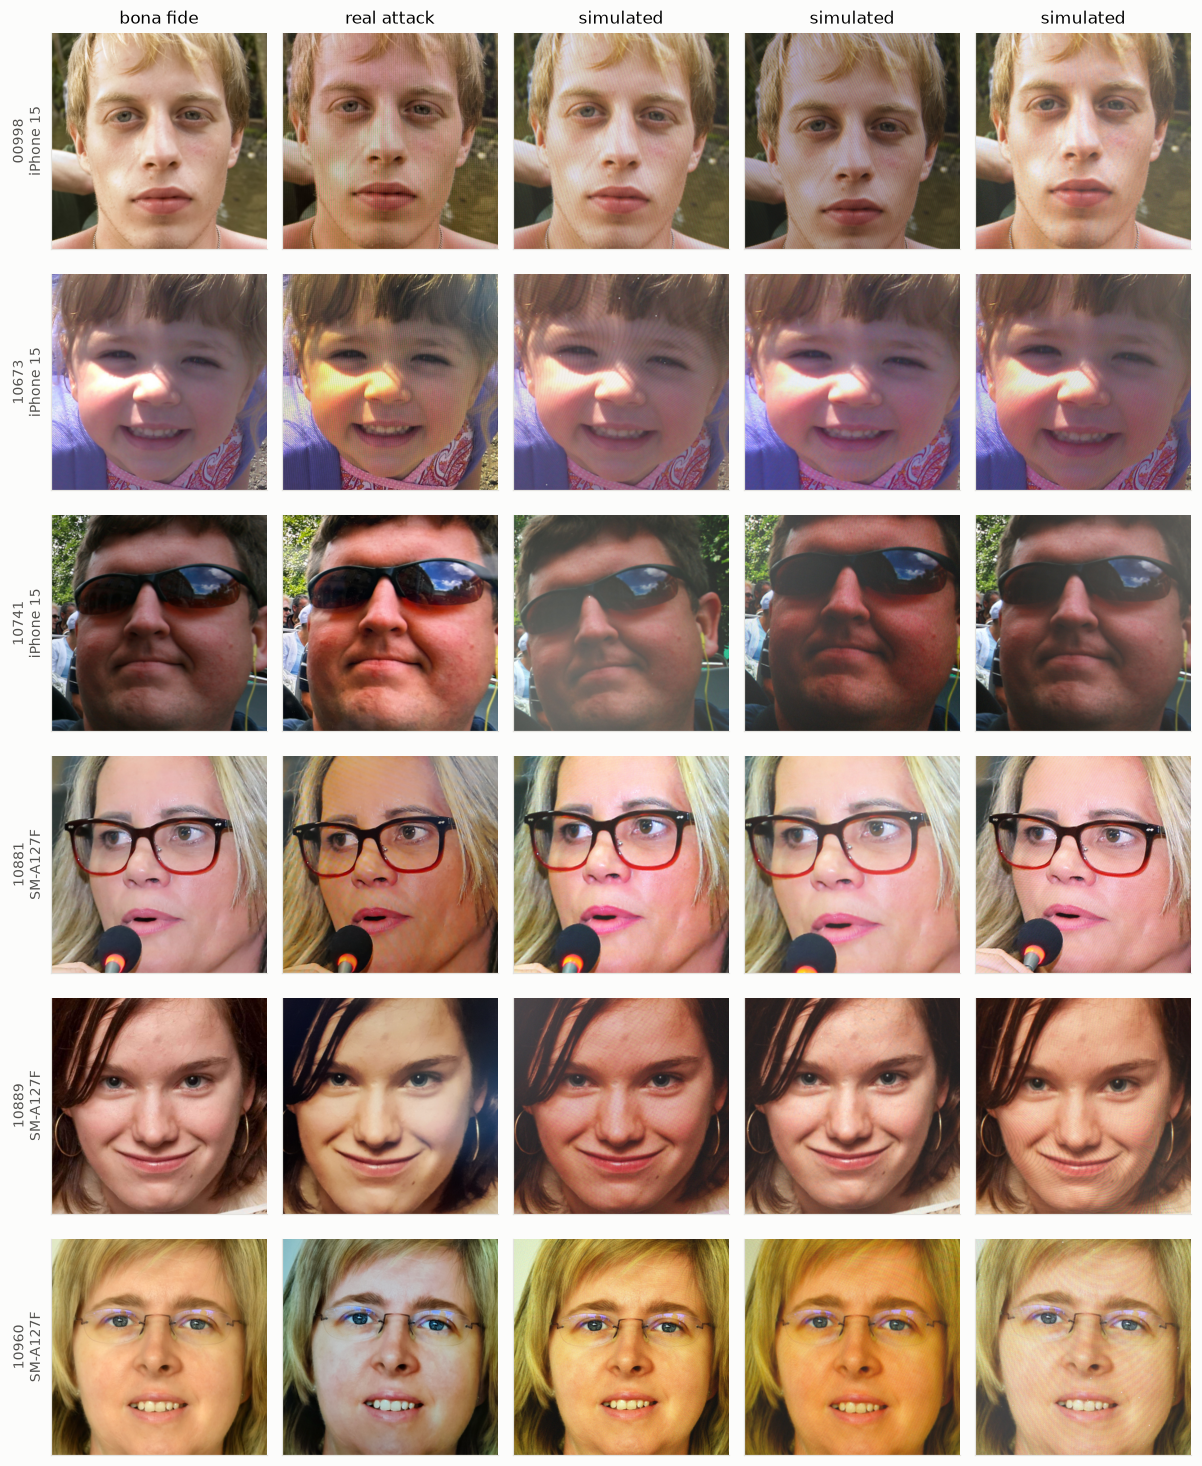

In [8]:
syn = load_cache(Path(cfg.data.cache_dir) / "synth_tight_384_dev.npz")
fs = cache_frame(syn)
fig, axes = plt.subplots(6, 5, figsize=(11, 13.5))
for r, i in enumerate(DEV_IDS):
    ims = [real["images"][(fr.id == i) & (fr.label == 0)][0], real["images"][(fr.id == i) & (fr.label == 1)][0]]
    ims += list(syn["images"][(fs.id == i) & (fs.kind == "synthetic_attack")][:3])
    for c, im in enumerate(ims):
        axes[r, c].imshow(im); axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        if r == 0:
            axes[r, c].set_title(["bona fide", "real attack", "simulated", "simulated", "simulated"][c])
    axes[r, 0].set_ylabel(f"{i}\n{phone[i]}")
plt.tight_layout(); plt.show()

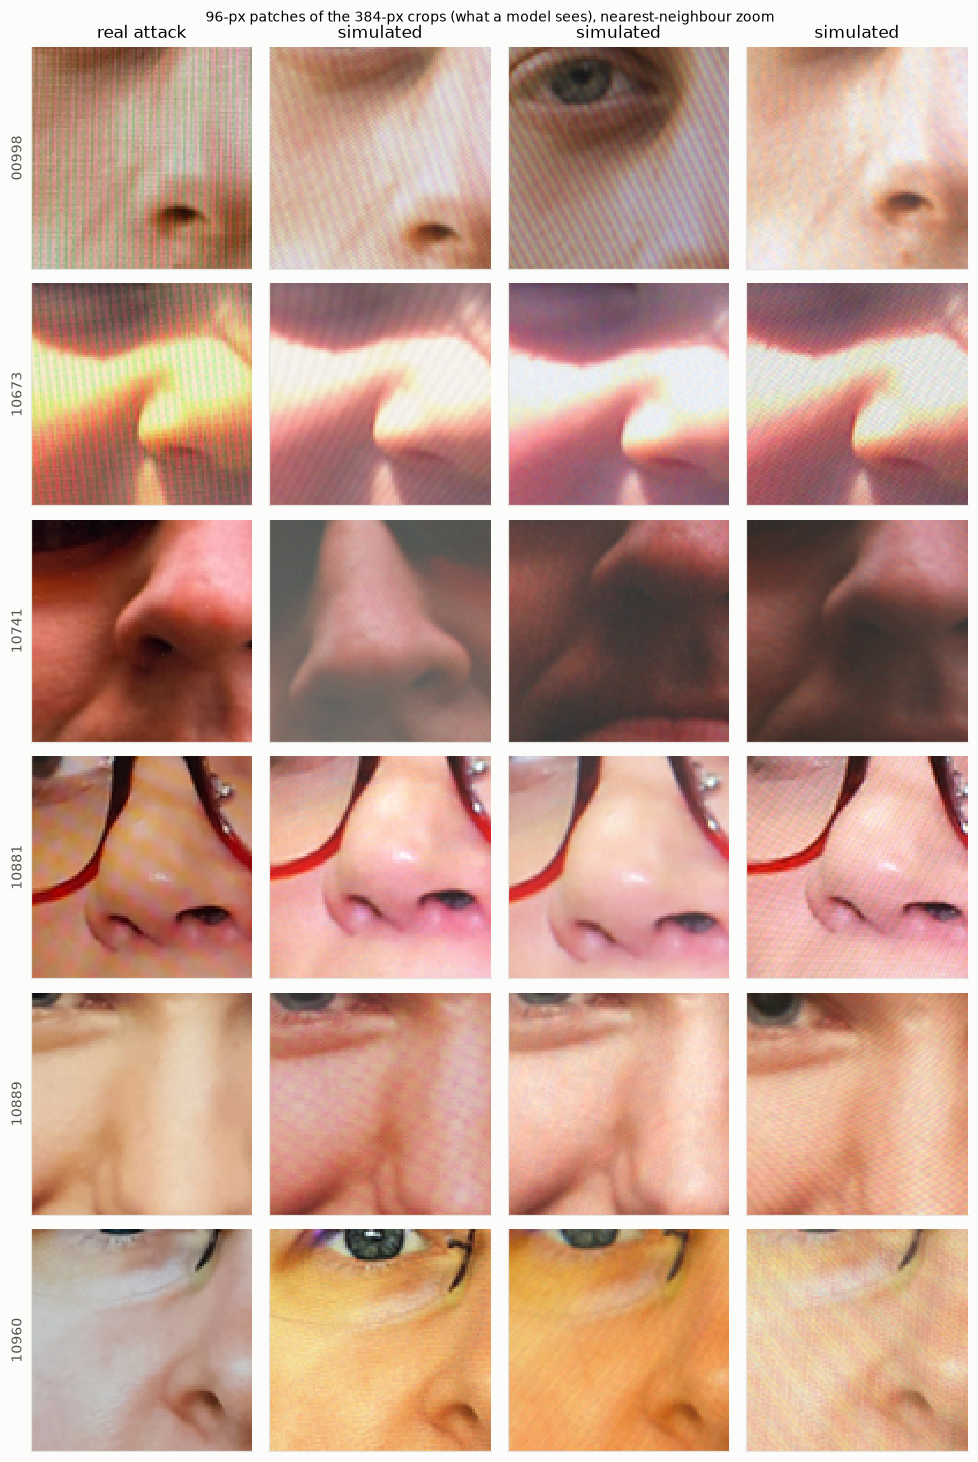

In [9]:
fig, axes = plt.subplots(6, 4, figsize=(9, 13.5))
for r, i in enumerate(DEV_IDS):
    ims = [real["images"][(fr.id == i) & (fr.label == 1)][0]] + list(syn["images"][(fs.id == i) & (fs.kind == "synthetic_attack")][:3])
    for c, im in enumerate(ims):
        axes[r, c].imshow(im[150:246, 100:196], interpolation="nearest"); axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        if r == 0:
            axes[r, c].set_title(["real attack", "simulated", "simulated", "simulated"][c])
    axes[r, 0].set_ylabel(i)
fig.suptitle("96-px patches of the 384-px crops (what a model sees), nearest-neighbour zoom", fontsize=9)
plt.tight_layout(); plt.show()

### Statistics: real vs simulated, and the camera-only control

The same per-crop statistics as the EDA, for four groups built from the same 6 dev identities:
- bona fide twins;
- **camera-only controls**: each twin through the camera stage alone, with no screen;
- real attacks;
- simulated attacks.

The camera-only group shows how much of each shift comes from the phone camera rather than the screen.

In [10]:
s_cam = (fs.kind == "camera_only").values
idx_b = [np.flatnonzero((fr.id == i) & (fr.label == 0))[0] for i in DEV_IDS]
idx_a = [np.flatnonzero((fr.id == i) & (fr.label == 1))[0] for i in DEV_IDS]
s_syn = (fs.kind == "synthetic_attack").values
groups = {
    "bona fide": (real["images"][idx_b], DEV_IDS, fr.info_resample_ratio.values[idx_b]),
    "camera only": (syn["images"][s_cam], list(fs.id[s_cam]), fs.info_resample_ratio.values[s_cam]),
    "real attack": (real["images"][idx_a], DEV_IDS, fr.info_resample_ratio.values[idx_a]),
    "simulated attack": (syn["images"][s_syn], list(fs.id[s_syn]), fs.info_resample_ratio.values[s_syn]),
}
frames = []
for g, (ims, ids, ratio) in groups.items():
    f = pixel_stats_frame(ims); f["group"], f["id"], f["crop downsample"] = g, ids, ratio
    frames.append(f)
st = pd.concat(frames, ignore_index=True)
COLS = ["brightness", "contrast", "saturation", "sharpness", "noise_sigma", "hf_ratio", "peak_score", "crop downsample"]
display(st.groupby("group")[COLS].median().T.round(3))

group,bona fide,camera only,real attack,simulated attack
brightness,52.558,53.161,47.716,48.232
contrast,18.063,19.923,18.698,18.041
saturation,0.384,0.436,0.415,0.330
sharpness,2.213,2.550,2.510,2.192
noise_sigma,1.449,1.984,1.784,2.117
hf_ratio,0.009,0.016,0.019,0.015
peak_score,1.483,1.417,1.603,2.215
crop downsample,1.841,4.179,4.839,4.478


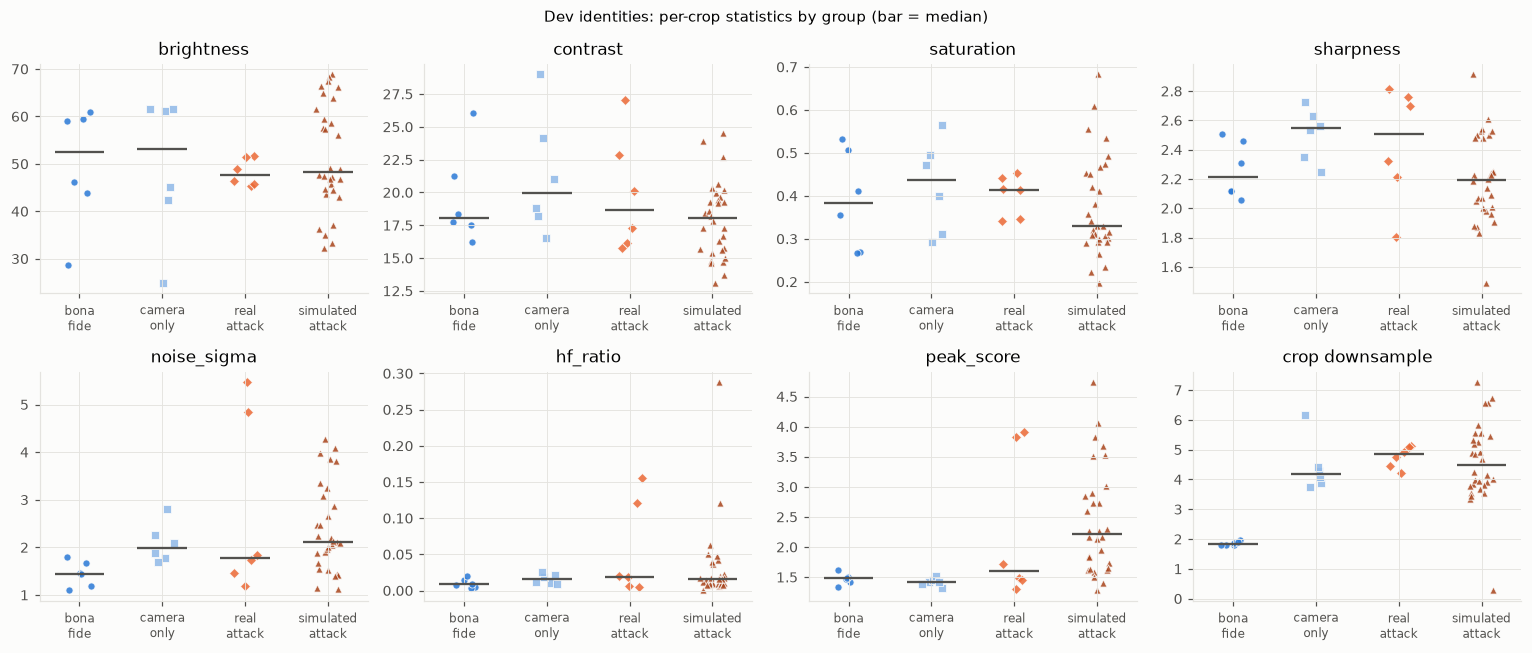

In [11]:
COLORS = {"bona fide": BONAFIDE_C, "camera only": CAMONLY_C, "real attack": ATTACK_C, "simulated attack": SYNTH_C}
MARKERS = {"bona fide": "o", "camera only": "s", "real attack": "D", "simulated attack": "^"}
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
rng_j = np.random.default_rng(0)
for ax, col in zip(axes.ravel(), COLS):
    for k, g in enumerate(COLORS):
        v = st.loc[st.group == g, col].values
        ax.scatter(k + rng_j.uniform(-0.15, 0.15, len(v)), v, s=22, color=COLORS[g], marker=MARKERS[g], alpha=0.85, edgecolor=SURFACE, linewidth=0.6)
        ax.hlines(np.median(v), k - 0.3, k + 0.3, color=INK_2, lw=1.5)
    ax.set_xticks(range(4)); ax.set_xticklabels([g.replace(" ", "\n") for g in COLORS], fontsize=8); ax.set_title(col)
fig.suptitle("Dev identities: per-crop statistics by group (bar = median)", fontsize=10)
plt.tight_layout(); plt.show()

In [12]:
b = st[st.group == "bona fide"].set_index("id")
shift_cols = ["brightness", "contrast", "saturation", "sharpness", "noise_sigma", "hf_ratio", "peak_score"]
rows = {}
for g in ("camera only", "real attack", "simulated attack"):
    x = st[st.group == g]
    d = x[shift_cols].values - b.loc[x["id"], shift_cols].values
    rows[g + ": median shift"] = np.median(d, 0)
    rows[g + ": fraction up"] = (d > 0).mean(0)
display(pd.DataFrame(rows, index=shift_cols).T.round(3))

,brightness,contrast,saturation,sharpness,noise_sigma,hf_ratio,peak_score
camera only: median shift,0.841,2.325,0.036,0.224,0.606,0.006,-0.042
camera only: fraction up,0.667,0.833,0.833,1.000,1.000,1.000,0.167
real attack: median shift,-3.743,0.238,0.051,0.206,0.355,0.003,0.199
real attack: fraction up,0.500,0.500,0.667,0.833,0.833,0.833,0.667
simulated attack: median shift,2.774,-1.605,-0.019,-0.056,0.773,0.007,0.753
simulated attack: fraction up,0.633,0.233,0.433,0.433,0.900,0.733,0.867


## 7. The resample-ratio shortcut

In the supplied data, how much a crop was downsampled separates the classes perfectly: bona fide 1.5-2.7x, real attacks 3.1-11x. If every synthetic attack were made at the dev phones' scale, the training set would carry the same perfect separator, and a model could learn "heavily downsampled" instead of "screen".

The simulator could make attacks at a smaller camera scale, so attack crops are downsampled less. A first version did, with `cam_per_src` down to 0.8, but at small scales the screen grid survived the crop far more strongly than in any real attack, which would make the synthetic task unrealistically easy.

Instead the shortcut is broken on the bona fide side. The **camera-only controls** are made at the same camera scale as the attacks (`cam_per_src` 1.5-3.5), so they are downsampled as hard as the attacks. The training bona fide class (raw FFHQ plus camera-only) then spans the attack range. Training also applies `rescale_jitter` to both classes.

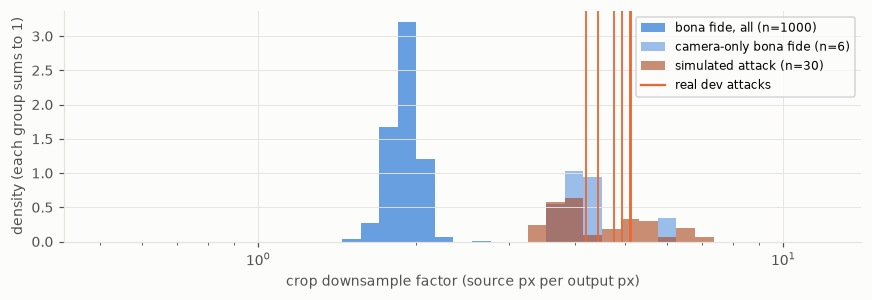

In [13]:
fig, ax = plt.subplots(figsize=(8, 2.8))
bins = np.geomspace(0.5, 12, 40)
all_b = fr.info_resample_ratio[fr.label == 0]
ax.hist(all_b, bins=bins, density=True, color=BONAFIDE_C, alpha=0.7, label=f"bona fide, all (n={len(all_b)})")
ax.hist(groups["camera only"][2], bins=bins, density=True, color=CAMONLY_C, alpha=0.9, label=f"camera-only bona fide (n={s_cam.sum()})")
ax.hist(groups["simulated attack"][2], bins=bins, density=True, color=SYNTH_C, alpha=0.6, label=f"simulated attack (n={s_syn.sum()})")
for v in groups["real attack"][2]:
    ax.axvline(v, color=ATTACK_C, lw=1.2)
ax.plot([], [], color=ATTACK_C, label="real dev attacks")
ax.set_xscale("log"); ax.set_xlabel("crop downsample factor (source px per output px)"); ax.set_ylabel("density (each group sums to 1)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Summary

**Measured on the dev pairs:**
- **The screen grid is the dominant, consistent cue at native resolution.** It appears as a periodic component of 3-7 camera pixels (stripes for LCD, softer or aliased into moiré on the Samsung captures). After the 384-px face crop it is much weaker.
- **Tone and colour change on every pair but in no consistent direction:** lifted or crushed blacks, compressed whites, warm or cool casts.
- **Fine image detail is lost** (screen resolution below source, lens blur), while **phone sharpening and noise** raise crop-level sharpness and noise.
- **The camera-only control moves sharpness, noise and high-frequency energy up too.** Those shifts are largely camera processing, not screen evidence, so using camera-only images as bona fide in training keeps them from becoming the cue.

**Simulator vs real (dev only, 5 draws per twin):**
- **Close to the real attacks:** brightness, contrast, noise, high-frequency energy and crop downsample factor (medians in the table above).
- **Remaining gaps**, left deliberately rather than tuned away on six images (results on the dev attacks will show whether they matter):
  - **Stronger isolated spectral peaks** in the simulated crops (`peak_score`, a median of about 2.2 against 1.6), so some synthetic attacks are easier than real ones. Lens blur was the main lever for this, and its range was raised once.
  - **Lower saturation** than the real attacks.
  - **Smaller sharpness gains** than the real attacks.
- **Downsample factors overlap across classes:** camera-only bona fide controls are downsampled as hard as attacks, so the resample ratio no longer separates the training classes.

**Calibration history** (all on dev, recorded here for the report): the first ranges gave washed-out, over-noisy and over-gridded crops. The changes made were:
- veil, black level and glare reduced;
- noise reduced;
- saturation, contrast and sharpening raised;
- lens blur raised;
- attack camera scale narrowed to 1.5-3.5.

**Not modelled:** screen refresh banding, finger or hand occlusion, curved screens, HDR merges, and video compression. They are absent from the dev attacks but could appear in the test set or a hidden set.